In [78]:
import numpy as np
import pandas as pd
import sympy as sp
import itertools
from numpy.linalg import lstsq
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy.integrate import solve_ivp
import torch
import torch.nn as nn

# Classes

In [79]:
# Define the PINN object
class PINN(nn.Module):
    def __init__(self, n_input, n_output, n_hidden, n_hidden_neurons=32):
        """
        Arguments:
        n_input    (int): Number of input features.
        n_outputs    (int): Number of output features.
        n_hidden    (int): Number of hidden layers.
        n_hidden_neurons (int): Number of neurons per hidden layer (32 by default).
        """
        super(PINN, self).__init__()
        layers = []

        # Input layer
        layers.append(nn.Linear(n_input, n_hidden_neurons))
        layers.append(nn.Tanh())

        # Hidden layers
        for _ in range(n_hidden - 1):
            layers.append(nn.Linear(n_hidden_neurons, n_hidden_neurons))
            layers.append(nn.Tanh())

        # Output layer
        layers.append(nn.Linear(n_hidden_neurons, n_output))

        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

# Functions

In [80]:
# RK4 implementation
def rk4(f,x,t,h,p):
    """
    Calcula un paso de integración del método de Runge Kutta orden 4.

    Argumentos de entrada:

        f : R^n -> R^n
        x = x(t) : R^n
        t = tiempo : R
        h = paso de tiempo : R
        p = parametros : R^q

    Retorna aproximacion numérica de

        x(t+h) : R^n

    según el método de Runge-Kutta de orden 4.

    # Ejemplos:
    """
    k1 = f(x,t,p)
    k2 = f(x+0.5*h*k1,t+0.5*h,p)
    k3 = f(x+0.5*h*k2,t+0.5*h,p)
    k4 = f(x+h*k3,t+h,p)
    return x+h*(k1+2.0*k2+2.0*k3+k4)/6.0

# ODE Integrator implementation
def integrador_ode(m,f,xa,t_0,t_f,t_total_steps,p,c=lambda x,t,p:x):
    """
    Integra numéricamente la ODE

        dx/dt = f(x,t)

    sobre el intervalo t:[a,b] usando k pasos de integración y el método m, bajo condicion inicial x(a)=x0.
    No es necesario que a<b.

    Argumentos de entrada:

        m = metodo de integracion (ej. euler, rk2, etc.)
        f : R^n -> R^n
        xa = condicion inicial : R
        a = tiempo inicial : R
        b = tiempo final : R
        k = num. pasos de integracion : N
        p = parametros : R^q
        c = función condicionante : R^n,R,p -> R^n

    Retorna:

        t : R^{k+1} , t_j = a+j*h para j=0,1,...,k
        w : R^{n,k+1} , w_ij = x_i(t_j) para i=0,1,...,n-1 y j=0,1,...,k

    donde a+k*dt = b.
    """
    k = t_total_steps
    a = t_0
    b = t_f
    assert k>0
    n = len(xa)
    h = (b-a)/k
    w = np.zeros((n,k+1)) # Produce un array con forma y tipo especificada con los parametros,
                          # lleno de ceros. la forma puede ser espcificada con un entero o tupla (n,k+1)
    t = np.zeros(k+1)
    w[:,0] = xa           # actualiza la posicion inicial (columna de indice 0) de las variables con los valores
                          # de las condiciones iniciales
    t[0] = a              # actualiza la posicion cero con el valor del tiempo inicial

    # Thresholds for detecting divergence
    
    max_magnitude = 1e20  # Arbitrarily large threshold
    min_magnitude = -1e20  # Arbitrarily small threshold

    for j in range(k):    #Aca se produce la iteración en j

        t[j+1] = t[j] + h                # iteracion tiempo
        try: 
            # Attempt integration step
            next_w = m(f, w[:, j], t[j], h, p)
            next_w = c(next_w, t[j + 1], p)

            # Check for divergence (inf/nan or extreme values)
            if (not np.all(np.isfinite(next_w)) or (np.any(next_w > max_magnitude)) or (np.any(next_w < min_magnitude))):
                raise RuntimeError("Divergence detected")

            w[:, j+1] = next_w
        except (RuntimeError, FloatingPointError):
            # On divergence, reuse previous state
            w[:, j+1] = w[:, j]

    return t,w.T

# Discovered ODE system
def discovered_system(Z,t,Xi):
    '''
    The fucntion returns the gLV set of ODEs defined by the matrix of coefficients Xi
    Inputs:
        Z: variables
        t: time
        Xi: Matrix of shape (n_terms x n_var)
    
    '''
    Theta = []
    Theta += [Z[i] for i in range(n_species)]  # Linear terms
    Theta += [Z[i]**2 for i in range(n_species)]  # Quadratic terms
    Theta += [Z[i] * Z[j] for i, j in itertools.combinations(range(n_species), 2)]  # Cross terms O(2)
    Theta = np.column_stack(Theta)

    derivatives = []
    for i in range(Xi.shape[1]):
        derivatives.append(Theta @ Xi[:, i])

    return np.hstack(derivatives)

# Plots learned trajectories and derivatives
def plot_pinn_learned_traj_and_deriv(model, t_colocation: torch.Tensor, w_data: np.ndarray, t_data_minmax: np.ndarray):
    '''
    Plots simulated population data, its derivative and the learned predictions with their derivatives
    Inputs:
        - model:            Trained model
        - t_colocation:     Pytorch Tensor with colocation time points
        - w_data:           Numpy array with simulated data
        - w_data_dot:       Numpy array with simulated data derivatives
        - t_data_minmax:    Simulated time rescaled from 0 to 1
    '''

    t_data_minmax = t_data_minmax.squeeze()
    
    # Plot predictions and simulated data
    pred = model(t_colocation)
    gradients = []
    for i in range(w_data.shape[1]):
        gradients.append(torch.autograd.grad(pred[:, i], t_colocation, grad_outputs=torch.ones_like(pred[:, i]), create_graph=True)[0].detach().cpu().numpy())
    pred_dot = np.column_stack(gradients)

    gradients = []
    for i in range(w_data.shape[1]):
        gradients.append(np.gradient(w_data[:, i], t_data_minmax))
    w_data_dot = np.column_stack(gradients)

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))

    # Plot time series data
    for i in range(w_data.shape[1]):
        ax[0].plot(t_data_minmax, w_data[:, i], label=f"sp{i+1}")
    ax[0].set_title("Trajectories")
    ax[0].set_xlabel("t")
    ax[0].grid(True, color='gray', linestyle='--', linewidth=0.5)
    #ax[0].set_xlim(-1,2)
    ax[0].legend()

    # Plot PINN learned prediction
    pred = pred.detach().cpu().numpy()
    for i in range(pred.shape[1]-1):
        ax[0].plot(t_colocation.cpu().detach().numpy(), pred[:, i], lw=1, linestyle='--', c='black')#, s=1)
    ax[0].plot(t_colocation.cpu().detach().numpy(), pred[:, i+1], lw=1, linestyle='--', c='black', label='PINN')
    ax[0].set_title("Trajectories")
    ax[0].set_xlabel("t")
    ax[0].grid(True, color='gray', linestyle='--', linewidth=0.5)
    ax[0].legend()

    # Plot time series data derivatives
    for i in range(w_data_dot.shape[1]):
        ax[1].plot(t_data_minmax, w_data_dot[:, i], label=f"sp{i+1}")#, label=labels[i])#, s=1)
    ax[1].set_title("Derivatives")
    ax[1].set_xlabel("t")
    ax[1].grid(True, color='gray', linestyle='--', linewidth=0.5)
    #ax[1].set_xlim(-1,2)
    ax[1].legend()

    # Plot PINN learned derivative
    pred_dot = pred_dot
    for i in range(pred_dot.shape[1]-1):
        ax[1].plot(t_colocation.cpu().detach().numpy(), pred_dot[:, i], lw=1, linestyle='--', c='black')#, s=1)
    ax[1].plot(t_colocation.cpu().detach().numpy(), pred_dot[:, i+1], lw=1, linestyle='--', c='black', label='PINN')
    ax[1].set_title("Derivative")
    ax[1].set_xlabel("t")
    ax[1].grid(True, color='gray', linestyle='--', linewidth=0.5)
    ax[1].legend()

    plt.tight_layout()
    plt.show()

# Compute library of polynomial terms up to order 2
def library_order_2(data:np.ndarray):
    '''
    Computes Theta matrix. The library of potential polynomial terms up to order 2
    Input:
        -X: A Numpy matrix of shape (time_steps x n_species)
    Output:
        -Theta: A Numpy matrix of shape (time_steps x terms)
    '''
    X = [data[:, i] for i in range(data.shape[1])] # len(X) = n_species
    
    Theta = []

    # Linear terms
    Theta += X

    # Quadratic terms
    Theta += [x**2 for x in X]

    # Cross terms
    Theta += [X[i] * X[j] for i,j in itertools.combinations(range(n_species), 2)]

    # Turn into a matrix
    Theta = np.column_stack(Theta)

    return Theta

# Akaike Information Criteria
def aic(test, pred, Xi):
    '''
    Computes the Akaike Informatio Criteria (AIC) with the correction for finite size samples:

                AIC = m * ln(RSS / m) + 2k + 2(k+1)(k+2)/(m-k-2)

    Inputs:
        test: Observation data - R^(timesteps x n_var)
        pred: Predicted data   - R^(timesteps x n_var)
        Xi:   Discovered coef. - R^(n_terms x n_var)
    '''
    m = test.shape[0]         # Number of of observations (time steps)
    k = np.count_nonzero(Xi)  # Number of non zero parameters in the discovered model

    rss = np.sum((test - pred)**2) # Compute the Residual Sum of Squares
    
    if m <= k + 1:
        return np.inf  # not enough data for reliable correction

    return 2 * k + m * np.log(rss/m) + 2 * (k + 1) * (k + 2) / (m - k - 2)

# Coefficients of the gLV model that are always present
def glv_protected_mask(n_species):
    '''
    Boolean mask of shape (n_terms, n_species) that marks the coefficients of Xi that are never
    thresholded: the intrinsic growth rate r_i (term x_i) and the self-regulation A_ii (term x_i^2)
    in the equation of species i. Only the interaction coefficients A_ij (i != j) can be set to zero.
    Inputs:
        - n_species: Number of species in the community
    '''
    n_terms = 2 * n_species + n_species * (n_species - 1) // 2
    protected = np.zeros((n_terms, n_species), dtype=bool)
    for i in range(n_species):
        protected[i, i] = True              # r_i
        protected[n_species + i, i] = True  # A_ii
    return protected

# Sparse regression for each state variable
def sparsify_dynamics(Theta, dXdt, lambda_, num_iter=10, Xi_pretrained = np.array([]), protected = None):
    '''
    Sequential Threshold Least Squares.
    Inputs:
        - Theta:          Library of candidate terms - R^(n_points, n_terms)
        - dXdt:           Derivatives                - R^(n_points, n_species)
        - lambda_:        Sparsity threshold
        - num_iter:       Number of threshold + least-squares iterations
        - Xi_pretrained:  Initial coefficients (least squares on Theta if empty)
        - protected:      Boolean mask with the shape of Xi; True entries are never thresholded (optional)
    '''
    n_outputs = dXdt.shape[1]
    if Xi_pretrained.size != 0:
        Xi = Xi_pretrained.copy()
    else:
        Xi = lstsq(Theta, dXdt, rcond=None)[0]  # shape (n_features, n_outputs)

    if protected is None:
        protected = np.zeros(Xi.shape, dtype=bool)

    Xi_history_stlsq = []
    Xi_history_stlsq.append(Xi)
    # Squential Thresholding
    for _ in range(num_iter):
        small_inds = (np.abs(Xi) < lambda_) & ~protected
        Xi[small_inds] = 0
        for i in range(n_outputs):
            big_inds = ~small_inds[:, i]
            if np.any(big_inds):
                Xi[big_inds, i] = lstsq(Theta[:, big_inds], dXdt[:, i], rcond=None)[0]
        Xi_history_stlsq.append(Xi)
    return Xi, Xi_history_stlsq

# Compute final infered interaction matrix A
def infered_interaction_matrix(Xi):
    '''
    Computes the interaction matrix A and linear term coefficients r from the coefficient matrix Xi via:

                        D^-1 * (Theta * Xi) = r + A * x
    Inputs:
        - Xi: Infered coefficients from the PINN-STLSq pipeline. Shape (n_terms, n_species)
    '''
    # Define symbols
    symb = []
    for i in range(n_species):
        symb.append(sp.symbols(f'x_{i+1}'))

    # Symbolic Library
    Theta = []
    Theta += [symb[i] for i in range(n_species)]  # Linear terms
    Theta += [symb[i]**2 for i in range(n_species)]  # Quadratic terms
    Theta += [symb[i] * symb[j] for i, j in itertools.combinations(range(n_species), 2)]  # Cross terms O(2)
    Theta = sp.Matrix(np.array(Theta)).T

    # Infered coefficients
    coef = sp.Matrix(Xi)

    # Diagonal matrix
    D = sp.Matrix(np.diag(symb))
    D_inv = D.inv()

    # Compute matrix multiplcation
    B = D_inv * (Theta * coef).T
    B = sp.simplify(B)

    # Variables
    v = sp.Matrix(symb)

    # Compute Jacobian (Interaction matrix A)
    A = B.jacobian(v)

    # Compute r = B - A*x
    r = B - A * v

    return r, A

# Relative Frobenius Norm metric
def RFN(Xi_ground_truth, Xi):
    '''
    Compute the Relative Frobenius Norm of Xi and Xi_ground_truth

                    RFN = |Xi - Xi_ground_truth| / |Xi_ground_truth|
    Inputs:
        -Xi: Inferred coefficients
        -Xi_ground_truth: Ground truth coefficients
    '''
    return np.linalg.norm(Xi - Xi_ground_truth) / np.linalg.norm(Xi_ground_truth)

# Support Accuracy metric
def SA(Xi_ground_truth, Xi):
    '''
    Computes the Support Accuray between Xi and Xi_ground_truth
    Inputs:
        -Xi: Inferred coefficients
        -Xi_ground_truth: Ground truth coefficients
    '''
    pred_support = (np.abs(Xi) > 1e-6).astype(int)
    true_support = (np.abs(Xi_ground_truth) > 1e-6).astype(int)
    return np.mean(pred_support == true_support)

# Plot learned trajectories and derivatives
def plot_multiIC_pinn_traj_and_deriv(nets, t_colocation: torch.Tensor, w_data: np.ndarray, t_data_minmax: np.ndarray, dpi=300):
    """
    Plots simulated trajectories and derivatives vs PINN predictions for multiple initial conditions.

    Rows:
        0 -> trajectories
        1 -> derivatives
    Columns:
        one per initial condition
    """

    num_init_cond = len(nets)
    n_species = w_data.shape[2]
    t_data_minmax = t_data_minmax.squeeze()

    fig, ax = plt.subplots(
        2, num_init_cond,
        figsize=(4 * num_init_cond, 6),
        dpi=dpi,
        sharex='col'
    )

    # Make ax indexable even if num_init_cond == 1
    if num_init_cond == 1:
        ax = np.array(ax).reshape(2, 1)

    for k in range(num_init_cond):

        model = nets[k]
        model.eval()

        # --------------------------------------------------
        # PINN predictions and derivatives
        # --------------------------------------------------
        t_col = t_colocation.clone().detach().requires_grad_(True)
        pred = model(t_col)

        pred_dot = []
        for i in range(n_species):
            dxi_dt = torch.autograd.grad(
                pred[:, i],
                t_col,
                grad_outputs=torch.ones_like(pred[:, i]),
                create_graph=True
            )[0]
            pred_dot.append(dxi_dt.detach().cpu().numpy())

        pred = pred.detach().cpu().numpy()
        pred_dot = np.column_stack(pred_dot)

        # --------------------------------------------------
        # Numerical derivative of data
        # --------------------------------------------------
        w_data_dot = []
        for i in range(n_species):
            w_data_dot.append(
                np.gradient(w_data[k][:, i], t_data_minmax)
            )
        w_data_dot = np.column_stack(w_data_dot)

        # --------------------------------------------------
        # Row 0: trajectories
        # --------------------------------------------------
        for i in range(n_species):
            ax[0, k].scatter(
                t_data_minmax,
                w_data[k][:, i],
                s=25,
                alpha=0.5,
                label=f"sp{i+1}" if k == 0 else None
            )

        for i in range(n_species):
            ax[0, k].plot(
                t_col.detach().cpu().numpy(),
                pred[:, i],
                linestyle='--',
                color='black',
                lw=1,
                label='PINN' if (i == n_species - 1 and k == 0) else None
            )

        ax[0, k].set_title(f"IC {k+1}")
        ax[0, k].grid(True, linestyle='--', alpha=0.4)

        # --------------------------------------------------
        # Row 1: derivatives
        # --------------------------------------------------
        for i in range(n_species):
            ax[1, k].scatter(
                t_data_minmax,
                w_data_dot[:, i],
                s=25,
                alpha=0.5,
                label=f"sp{i+1}" if k == 0 else None
            )

        for i in range(n_species):
            ax[1, k].plot(
                t_col.detach().cpu().numpy(),
                pred_dot[:, i],
                linestyle='--',
                color='black',
                lw=1
            )

        ax[1, k].set_xlabel("t")
        ax[1, k].grid(True, linestyle='--', alpha=0.4)

    # Axis labels
    ax[0, 0].set_ylabel("Population")
    ax[1, 0].set_ylabel("d/dt")

    # Legends (only once)
    ax[0, 0].legend()
    #ax[1, 0].legend()

    plt.tight_layout()
    plt.show()

# Plot MSE and AIC
def plot_mse_aic_vs_lambda_many_IC(pareto_data_dict, dpi):
    """
    Plots (1) trajectory MSE, (2) derivative MSE, and (3) AIC vs sparsity threshold λ.
    For multi-IC case:
      - thin curves: per-IC values
      - thick curve: average across ICs
    """

    lambdas = np.array(pareto_data_dict['lambdas'])
    idx = pareto_data_dict['aic_min_lambda_idx']
    lambda_value = lambdas[idx]

    mse_deriv_list  = np.array(pareto_data_dict['mse_deriv_list'])         # (n_lambda, num_IC)
    mse_deriv_avrg  = np.array(pareto_data_dict['mse_deriv_avrg'])  
    mse_traj_list   = np.array(pareto_data_dict['mse_traj_list'])     # (n_lambda, num_IC)
    mse_traj_avrg   = np.array(pareto_data_dict['mse_traj_avrg'])
    aic_list        = np.array(pareto_data_dict['aic_values_list'])   # (n_lambda, num_IC)
    aic_avrg        = np.array(pareto_data_dict['aic_values_avrg'])

    num_init_cond = mse_traj_list.shape[1]

    fig, ax = plt.subplots(1, 3, figsize=(15, 4), dpi=dpi)

    # ==========================================================
    # 1) Trajectory MSE
    # ==========================================================
    for k in range(num_init_cond):
        ax[0].plot(
            lambdas, mse_traj_list[:, k],
            color='purple', alpha=0.3, linewidth=1
        )

    ax[0].plot(
        lambdas, mse_traj_avrg,
        marker='o', markersize=5, linewidth=2.5,
        color='purple', label=r'Average $\mathrm{MSE}_{\mathbf{X}}$'
    )

    ax[0].axvline(
        x=lambda_value, color='black', linestyle='--',
        linewidth=1.5, label=r'Selected $\lambda$'
    )

    ax[0].grid(True, alpha=0.5, linestyle='--', lw=0.5)
    ax[0].ticklabel_format(style='sci', axis='y', scilimits=(0, 0))
    ax[0].set_xlabel(r'$\lambda$')
    ax[0].set_ylabel(r'$\mathrm{MSE}_{\mathbf{X}}$')
    ax[0].legend()

    # ==========================================================
    # 2) Derivative MSE
    # ==========================================================
    for k in range(num_init_cond):
        ax[1].plot(
            lambdas, mse_deriv_list[:, k],
            color='blue', alpha=0.3, linewidth=1
        )
    ax[1].plot(
        lambdas, mse_deriv_avrg,
        marker='o', markersize=5, linewidth=2.5,
        color='blue', label=r'$\mathrm{MSE}_{\dot{\mathbf{X}}}$'
    )

    ax[1].axvline(
        x=lambda_value, color='black', linestyle='--',
        linewidth=1.5, label=r'Selected $\lambda$'
    )

    ax[1].grid(True, alpha=0.5, linestyle='--', lw=0.5)
    ax[1].ticklabel_format(style='sci', axis='y', scilimits=(0, 0))
    ax[1].set_xlabel(r'$\lambda$')
    ax[1].set_ylabel(r'$\mathrm{MSE}_{\dot{\mathbf{X}}}$')
    ax[1].legend()

    # ==========================================================
    # 3) AIC
    # ==========================================================
    for k in range(num_init_cond):
        ax[2].plot(
            lambdas, aic_list[:, k],
            color='olive', alpha=0.3, linewidth=1
        )

    ax[2].plot(
        lambdas, aic_avrg,
        marker='o', markersize=5, linewidth=2.5,
        color='olive', label='Average AIC'
    )

    ax[2].axvline(
        x=lambda_value, color='black', linestyle='--',
        linewidth=1.5, label=r'Selected $\lambda$'
    )

    ax[2].grid(True, alpha=0.5, linestyle='--', lw=0.5)
    ax[2].ticklabel_format(style='sci', axis='y', scilimits=(0, 0))
    ax[2].set_xlabel(r'$\lambda$')
    ax[2].set_ylabel('AIC')
    ax[2].legend()

    plt.tight_layout()
    plt.show()

# Plot only AIC
def plot_aic_vs_lambda_many_IC(pareto_data_dict, dpi):
    """
    Plots AIC vs sparsity threshold λ.
    For multi-IC case:
      - thin curves: per-IC values
      - thick curve: average across ICs
    """

    lambdas = np.array(pareto_data_dict['lambdas'])
    idx = pareto_data_dict['aic_min_lambda_idx']
    lambda_value = lambdas[idx]

    aic_list = np.array(pareto_data_dict['aic_values_list'])   # (n_lambda, num_IC)
    aic_avrg = np.array(pareto_data_dict['aic_values_avrg'])

    num_init_cond = aic_list.shape[1]

    fig, ax = plt.subplots(1, 1, figsize=(7, 4), dpi=dpi)

    # ==========================================================
    # AIC
    # ==========================================================
    for k in range(num_init_cond):
        ax.plot(
            lambdas, aic_list[:, k],
            color='olive', alpha=0.3, linewidth=1
        )

    ax.plot(
        lambdas, aic_avrg,
        marker='o', markersize=5, linewidth=2.5,
        color='olive', label='Average AIC'
    )

    ax.axvline(
        x=lambda_value, color='black', linestyle='--',
        linewidth=1.5, label=r'Selected $\lambda$'
    )

    ax.grid(True, alpha=0.5, linestyle='--', lw=0.5)
    ax.ticklabel_format(style='sci', axis='y', scilimits=(0, 0))
    ax.set_xlabel(r'$\lambda$')
    ax.set_ylabel('AIC')
    ax.legend()

    plt.tight_layout()
    plt.show()

# Plot final sparsest discovered trajectory and derivative for each IC
def plot_final_traj_and_deriv_multiIC(
    pareto_data_dict,
    test,
    test_dot,
    t_test,
    N,
    dpi=120,
    idx=None
):
    """
    Plots discovered trajectories and derivatives vs test data
    for multiple initial conditions (ICs).

    Layout:
        Rows:    [Trajectories, Derivatives]
        Columns: one per IC
    """

    if idx is None:
        idx = pareto_data_dict['aic_min_lambda_idx']

    # Unpack discovered trajectories and derivatives
    # Shapes:
    #   pred_traj : (num_IC, T, n_species)
    #   pred_dot  : (num_IC, T, n_species)
    pred_traj = pareto_data_dict['disc_traj_list'][idx]
    pred_dot  = pareto_data_dict['disc_deriv_list'][idx]

    num_init_cond, _, n_species = pred_traj.shape

    # Reshape test data if necesary
    test = test.reshape(num_init_cond, -1, n_species)
    test_dot = test_dot.reshape(num_init_cond, -1, n_species)
    
    fig, ax = plt.subplots(
        2,
        num_init_cond,
        figsize=(4 * num_init_cond, 6),
        dpi=dpi,
        sharex=True
    )

    if num_init_cond == 1:
        ax = np.array(ax).reshape(2, 1)

    # Labels and colors
    traj_labels = [rf"$x_{i+1}(t)$" for i in range(n_species)]
    deriv_labels = [rf"$\dot{{x}}_{i+1}(t)$" for i in range(n_species)]
    colors = ['darkgreen', 'darkred', 'darkblue', 'darkorange']

    for k in range(num_init_cond):

        # -----------------------------
        # Trajectories
        # -----------------------------
        for i in range(n_species):
            ax[0, k].scatter(
                t_test[::N],
                test[k, ::N, i],
                s=25,
                alpha=0.5,
                color=colors[i],
                label=traj_labels[i] if k == 0 else None
            )
            ax[0, k].plot(
                t_test,
                pred_traj[k, :, i],
                lw=2,
                color=colors[i],
                label=r"Inferred" if (k == 0 and i == 0) else None
            )

        ax[0, k].set_title(f"IC {k+1}")
        ax[0, k].grid(True, linestyle='--', alpha=0.4)

        # -----------------------------
        # Derivatives
        # -----------------------------
        for i in range(n_species):
            ax[1, k].scatter(
                t_test[::N],
                test_dot[k, ::N, i],
                s=25,
                alpha=0.5,
                color=colors[i],
                label=deriv_labels[i] if k == 0 else None
            )
            ax[1, k].plot(
                t_test,
                pred_dot[k, :, i],
                lw=2,
                color=colors[i],
                label=r"Discovered" if (k == 0 and i == 0) else None
            )

        ax[1, k].set_xlabel("t")
        ax[1, k].grid(True, linestyle='--', alpha=0.4)

    ax[0, 0].set_ylabel("Trajectories")
    ax[1, 0].set_ylabel("Derivatives")

    # Global legend
    handles, labels = ax[0, 0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="upper center",
        ncol=2 + n_species,
        frameon=False
    )

    plt.tight_layout(rect=[0, 0, 1, 0.92])
    plt.show()

# Print final result and error metrics
def print_results(control_data, pareto_data_dict, idx=None):
    """
    Prints final discovered model, sparsity, and identification metrics.
    Metrics are global (shared across ICs).
    """

    if idx is None:
        idx = pareto_data_dict['aic_min_lambda_idx']

    # -----------------------
    # Unpack values
    # -----------------------
    lambda_value = pareto_data_dict['lambdas'][idx]
    Xi = pareto_data_dict['Xi_disc'][idx]
    Xi_truth = control_data['Xi_ground_truth'][0]
    noise_amplitude = control_data['noise_amplitude'][0]

    # Optional (multi-IC trajectories)
    pred_traj = pareto_data_dict['disc_traj_list'][idx]
    pred_dot  = pareto_data_dict['disc_deriv_list'][idx]

    num_init_cond, _, n_species = pred_traj.shape

    # -----------------------
    # Print model info
    # -----------------------
    print("\n-==================== Sparsity in ST-LSq ====================-")
    print(f"Sparsity Threshold (λ): {lambda_value:.7f}")
    print(f"Noise Amplitude       : {noise_amplitude * 100:.2f}%")
    print(f"Number of ICs         : {num_init_cond}")

    print("\n-==================== Ground Truth Xi ====================-")
    print(Xi_truth)

    print("\n-==================== Identified Xi ====================-")
    print(Xi)

    # -----------------------
    # Coefficient error metrics
    # -----------------------
    mse = []
    rel_err = []
    rel_err_nz = []

    for i in range(Xi.shape[1]):

        # MSE per state equation
        mse.append(np.mean((Xi[:, i] - Xi_truth[:, i]) ** 2))

        # Relative error
        rel_err.append(
            np.linalg.norm(Xi[:, i] - Xi_truth[:, i]) /
            np.linalg.norm(Xi_truth[:, i])
        )

        # Relative error on non-zero coefficients (truth-based)
        nz_mask = Xi_truth[:, i] != 0
        if np.any(nz_mask):
            rel_err_nz.append(
                np.mean(
                    np.abs(
                        (Xi[nz_mask, i] - Xi_truth[nz_mask, i]) /
                        Xi_truth[nz_mask, i]
                    )
                )
            )
        else:
            rel_err_nz.append(np.nan)

    # -----------------------
    # Global metrics
    # -----------------------
    model_mse = np.mean((Xi - Xi_truth) ** 2)
    model_mre_nz = np.nanmean(rel_err_nz)
    frob_norm = np.linalg.norm(Xi - Xi_truth)
    frob_norm_rel = frob_norm / np.linalg.norm(Xi_truth)
    support_accuracy = SA(Xi_truth, Xi)

    # -----------------------
    # Metrics table
    # -----------------------
    df_metrics = pd.DataFrame({
        "Variable": [f"x{i+1}" for i in range(Xi.shape[1])],
        "MSE": mse,
        "Relative Error": rel_err,
        "Relative Error (NZ)": rel_err_nz
    })

    df_metrics.loc[len(df_metrics)] = [
        "Model (global)",
        model_mse,
        np.nan,
        model_mre_nz
    ]

    pd.set_option("display.precision", 4)
    print("\n-==================== Error Metrics Table ====================-")
    print(df_metrics.to_string(index=False))

    # -----------------------
    # Global summary
    # -----------------------
    print("\n-==================== Global Summary ====================-")
    print(f"Frobenius Norm            : {frob_norm:.4e}")
    print(f"Relative Frobenius Norm   : {frob_norm_rel:.4e}")
    print(f"Support Accuracy          : {support_accuracy:.4f}")

# Implementation

# Loading the trained PINN to generate colocation points and perform ST-LSq

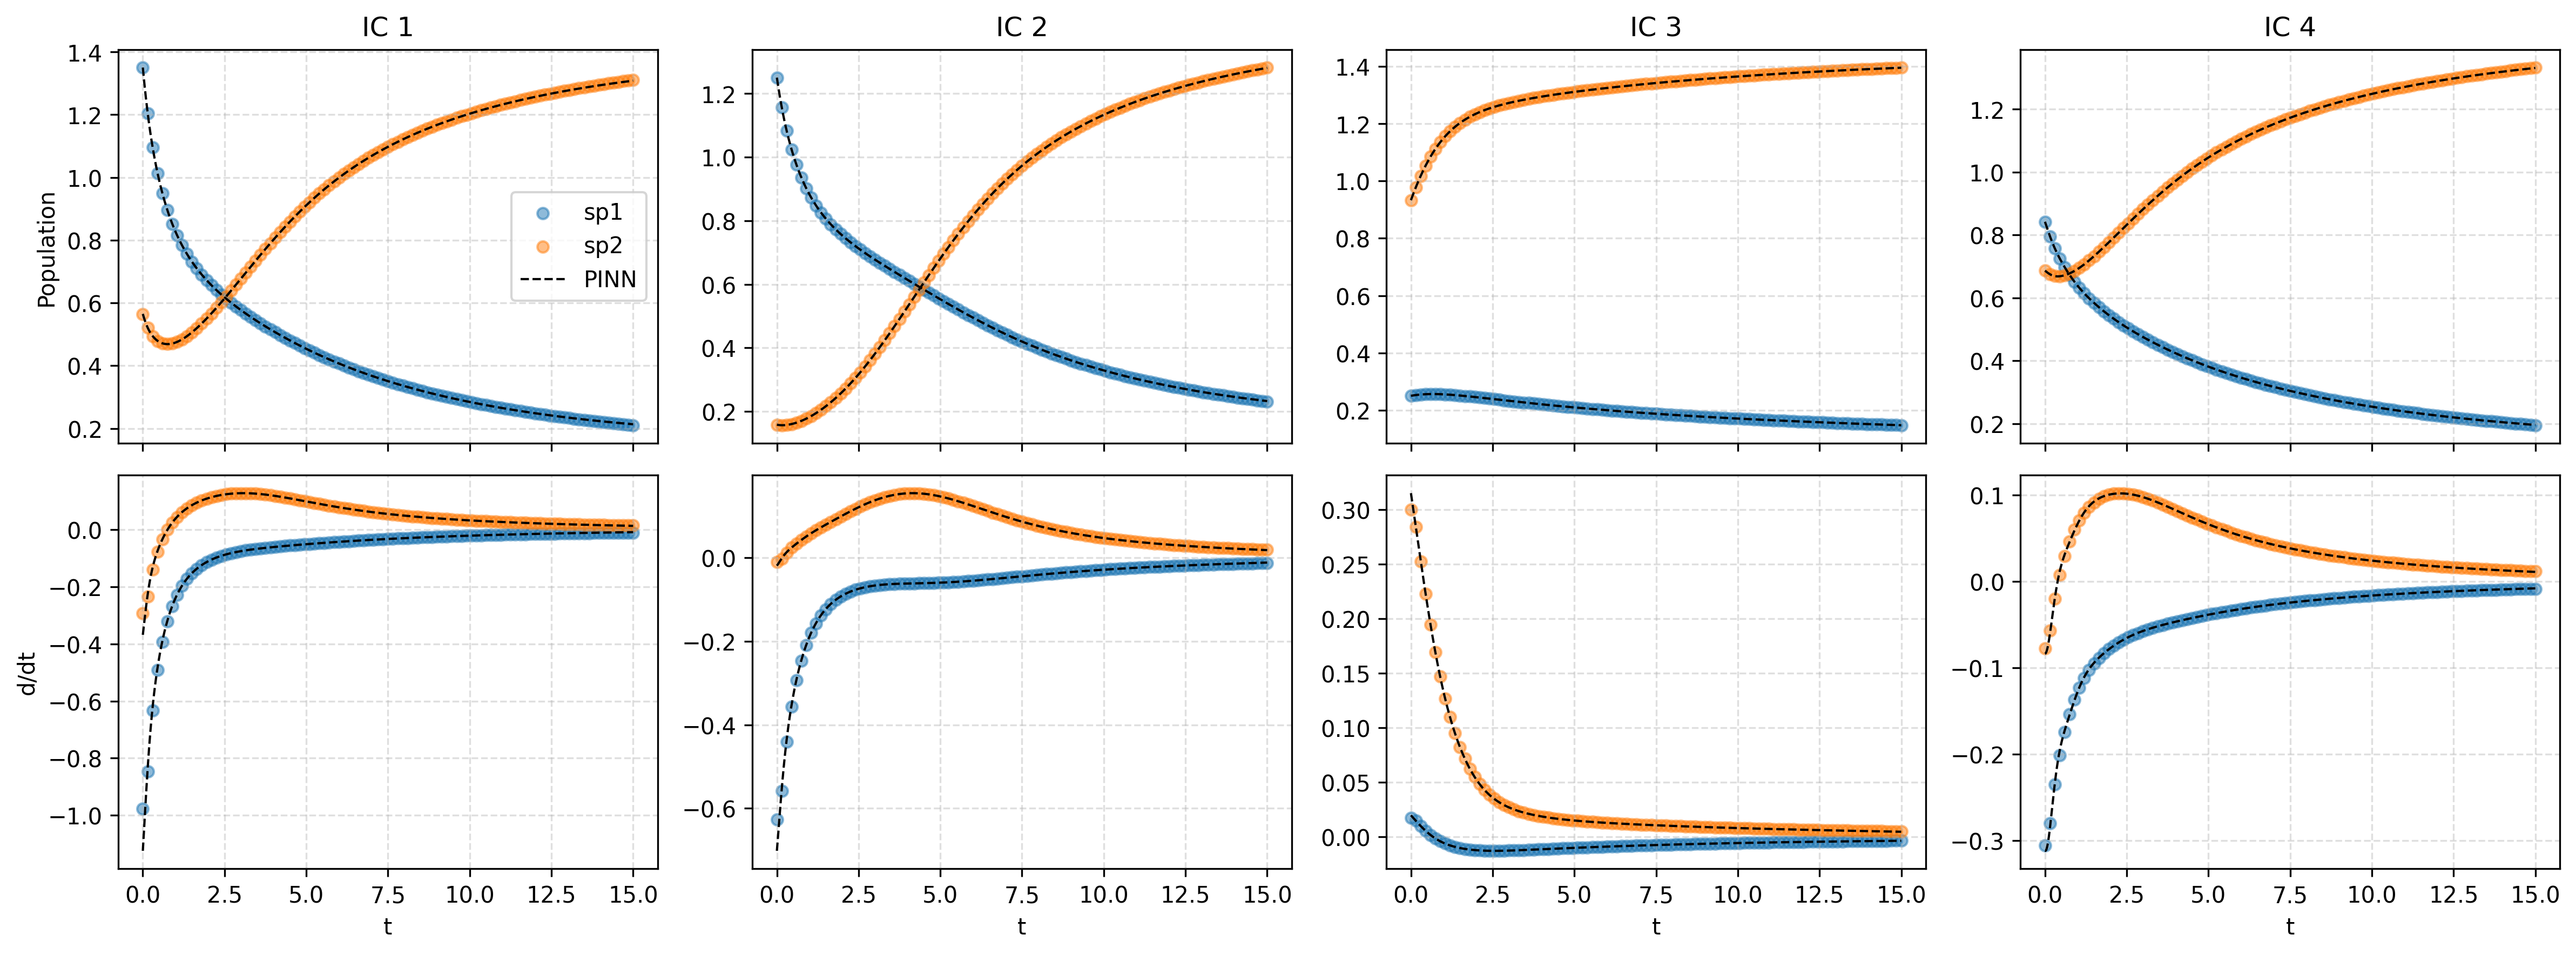

In [81]:
# Load data
control_data = np.load('constr_data_4_IC_for_STLSq-RSEED_6-2_species-0%_noise-100_timesteps-120kEpc-lock_at_80k.npy', allow_pickle=True).item()
num_init_cond = len(control_data['trained_networks'][0])

# Retrieve number of species in the community
n_species = control_data['simulated_data'][0].shape[2]

# Retrieve trained PINN
nets = []
for k in range(num_init_cond):
    pinn_model = PINN(n_input=1, n_output=n_species, n_hidden=3)
    pinn_model.load_state_dict(control_data['trained_networks'][0][k])
    pinn_model.to('cpu')
    nets.append(pinn_model)

# Retrieve inital guess of the coefficients
Xi_pretrained = control_data['Xi_over_training'][0][-1]

# Retrieve simulated data, time and derivative
w_data = control_data['simulated_data'][0]
t = control_data['simulated_data_t'][0]
w_data_dot = control_data['simulated_data_dot'][0]


# Define colocation points for plotting
t_colocation = torch.linspace(t.min(), t.max(), 1000).reshape(-1,1).requires_grad_().to('cpu')

plot_multiIC_pinn_traj_and_deriv(nets, t_colocation, w_data, t, dpi=300)

## 1\) Generate colocation points using the trained PINNs

In [82]:
# Generate colocation points and compute the derivative with autograd
colocations = []
colocations_dot = []
for k in range(num_init_cond):
    pinn_model = nets[k]
    coloc = pinn_model(t_colocation)
    gradients = []
    for i in range(coloc.shape[1]):
        grad_i = torch.autograd.grad(coloc[:, i],
                                            t_colocation,
                                            grad_outputs=torch.ones_like(coloc[:, i]),
                                            create_graph=True)[0]
        gradients.append(grad_i.detach().cpu().numpy())
    coloc_dot = np.hstack(gradients)
    colocations.append(coloc.detach().cpu().numpy())
    colocations_dot.append(coloc_dot)

# Detach and turn Tensors into Numpy arrays
t_coloc = t_colocation.detach().cpu().numpy()

# Transform everything into numpy
coloc = np.array(colocations)
coloc_dot = np.array(colocations_dot)

# Shape consistency check
print("Colocation data shapes:")
print(f"    coloc :     {coloc.shape}")
print(f"    coloc_dot : {coloc_dot.shape}\n")

# Stack colocation points
coloc = np.vstack(coloc)
coloc_dot = np.vstack(coloc_dot)

# Shape of stacked colocations for sanity check
print("Reshaped colocation data shapes:")
print(f"    coloc :     {coloc.shape}")
print(f"    coloc_dot : {coloc_dot.shape}")


# Compute the library of functions using the colocation points
Theta = library_order_2(data=coloc)
print(f"    Theta :     {Theta.shape}")

Colocation data shapes:
    coloc :     (4, 1000, 2)
    coloc_dot : (4, 1000, 2)

Reshaped colocation data shapes:
    coloc :     (4000, 2)
    coloc_dot : (4000, 2)
    Theta :     (4000, 5)


## 2\) Generate test set

In [83]:
# Use the trained PINN to generate test data
t_test = torch.linspace(t.min(), t.max(), 800).reshape(-1, 1).requires_grad_().to('cpu')

tests = []
tests_dot = []
for k in range(num_init_cond):
    pinn_model = nets[k]
    test = pinn_model(t_test)
    gradients = []
    for i in range(n_species):
        grad_i = torch.autograd.grad(test[:, i], t_test,
                                    grad_outputs=torch.ones_like(test[:, i]),
                                    create_graph=True)[0]
        gradients.append(grad_i.detach().cpu().numpy())
    test_dot = np.hstack(gradients)
    tests.append(test.detach().cpu().numpy())
    tests_dot.append(test_dot)

# Detach and turn tensors into Numpy arrays
t_test = t_test.detach().cpu().numpy()

# Transform everything into numpy
test = np.array(tests)
test_dot = np.array(tests_dot)

# Shape consistency check
print("Test data shapes:")
print(f"    test :      {test.shape}")
print(f"    test_dot :  {test_dot.shape}\n")

# Stack test points
test = np.vstack(test)
test_dot = np.vstack(test_dot)

# Shape of stacked test points for sanity check
print("Reshaped test data shapes:")
print(f"    test :     {test.shape}")
print(f"    test_dot : {test_dot.shape}")

# Compute the library of functions using the test points
Theta_test = library_order_2(test)
print(f"    Theta_test: {Theta_test.shape}")

Test data shapes:
    test :      (4, 800, 2)
    test_dot :  (4, 800, 2)

Reshaped test data shapes:
    test :     (3200, 2)
    test_dot : (3200, 2)
    Theta_test: (3200, 5)


## 3\) Solve optimization problem via ST-LSq:
 - 3.1\) Predict derivatives
 - 3.2\) Compute MSE of predicted vs test derivatives
 - 3.3\) Integrate predicted ODEs (predicted trajectories)
 - 3.4\) Compute MSE of predicted vs test trajectories
 - 3.5\) Compute AIC

In [84]:
# Sparsity thresholds
lambdas = np.linspace(0.1, 0.9, 100)

# Akaike information criteria values
aic_min = 1e10
aic_min_lambda = 1e10
aic_min_lambda_idx = 1e10

# Dictionary for saving values across threshold values
pareto_data_dict = {'lambdas'                : [],
                    'mse_deriv_list'         : [],
                    'mse_deriv_avrg'         : [],
                    'mse_traj_list'          : [],
                    'mse_traj_avrg'          : [],
                    'Xi_disc'                : [],
                    'Xi_disc_history'        : [],
                    'disc_traj_list'         : [],
                    'disc_deriv_list'        : [],
                    'aic_values_list'        : [],
                    'aic_values_avrg'        : [],
                    'aic_min_lambda_list'    : [],
                    'aic_min_lambda_idx_list': []
                    }

# Create re-shape of test data for trajectory MSE and AIC computation
test_expanded = test.reshape(num_init_cond, -1, n_species)
test_dot_expanded = test_dot.reshape(num_init_cond, -1, n_species)
Theta_test_expanded = Theta_test.reshape(num_init_cond, -1, Theta_test.shape[1])

# Unpack integration parameters from simulated data
integr_param = control_data['numeric_integr_param'][0]

# Growth rates r_i and self-regulation A_ii are never thresholded
protected = glv_protected_mask(n_species)

for lambda_threshold in lambdas:

    # 3) Sequential Threshold Least Squares
    Xi, Xi_history_stlsq = sparsify_dynamics(Theta, coloc_dot, lambda_threshold, num_iter=10, Xi_pretrained=Xi_pretrained, protected=protected)
    #Xi, Xi_history_stlsq = sparsify_dynamics(Theta, coloc_dot, lambda_threshold, num_iter=10, Xi_pretrained=np.array([]), protected=protected)
    
    # 3.1) Predicted derivatives
    gradients = []
    for i in range(Xi.shape[1]):
        gradients.append(Theta_test @ Xi[:, i])
    pred_dot = np.vstack(gradients).T
    pred_dot_expanded = pred_dot.reshape(num_init_cond, -1, n_species)

    # Save mse of predicted derivatives for each IC
    mse_deriv_per_IC = []
    for k in range(num_init_cond):
        pred_dot_k = pred_dot_expanded[k]
        test_dot_k = test_dot_expanded[k]
        mse_deriv_k = np.mean((pred_dot_k - test_dot_k)**2)
        mse_deriv_per_IC.append(mse_deriv_k)
        
            

    # 3.2) Compute MSE of predicted vs test derivatives
    mse_deriv = np.mean((pred_dot - test_dot) ** 2)

    # 3.3) Integrate predicted ODEs (compute predicted trajectories)
    x0_list = control_data['simulated_init_cond'][0]
    preds = []
    mse_traj_per_IC = []
    aic_per_IC = []
    for k in range(num_init_cond):
        x0 = x0_list[k]
        test_k = test_expanded[k]
        _, pred_k = integrador_ode(rk4, discovered_system, x0,
                                t_0 = t_test[0,0],
                                t_f = t_test[-1,0],
                                t_total_steps = len(t_test)-1,
                                p=Xi)
        
        # Compute MSE of the trajectory for the current IC
        mse_traj_k = np.mean((pred_k - test_k)**2)

        # Compute AIC of the trajectory for current IC
        aic_k = aic(test_k, pred_k, Xi)

        # Save values
        preds.append(pred_k)
        mse_traj_per_IC.append(mse_traj_k)
        aic_per_IC.append(aic_k)
    
    # Reshape trajectories into numpy array
    preds = np.array(preds)
    
    # 3.4) Compute average MSE of predicted vs test trajectories
    mse_traj = np.mean(mse_traj_per_IC)

    # 3.5) Compute average AIC
    aic_value = np.mean(aic_per_IC)

    # Save lambda that minimizes AIC
    if aic_value <= aic_min:
        aic_min = aic_value
        pareto_data_dict['aic_min_lambda'] = lambda_threshold
        pareto_data_dict['aic_min_lambda_idx'] = np.where(lambdas == lambda_threshold)[0][0]

    # Save results for current lambda value
    pareto_data_dict['lambdas'].append(lambda_threshold)
    pareto_data_dict['mse_deriv_list'].append(mse_deriv_per_IC)
    pareto_data_dict['mse_deriv_avrg'].append(mse_deriv)
    pareto_data_dict['mse_traj_list'].append(mse_traj_per_IC)
    pareto_data_dict['mse_traj_avrg'].append(mse_traj)
    pareto_data_dict['Xi_disc'].append(Xi)
    pareto_data_dict['Xi_disc_history'].append(Xi_history_stlsq)
    pareto_data_dict['disc_traj_list'].append(preds)
    pareto_data_dict['disc_deriv_list'].append(pred_dot_expanded)
    pareto_data_dict['aic_values_list'].append(aic_per_IC)
    pareto_data_dict['aic_values_avrg'].append(aic_value)

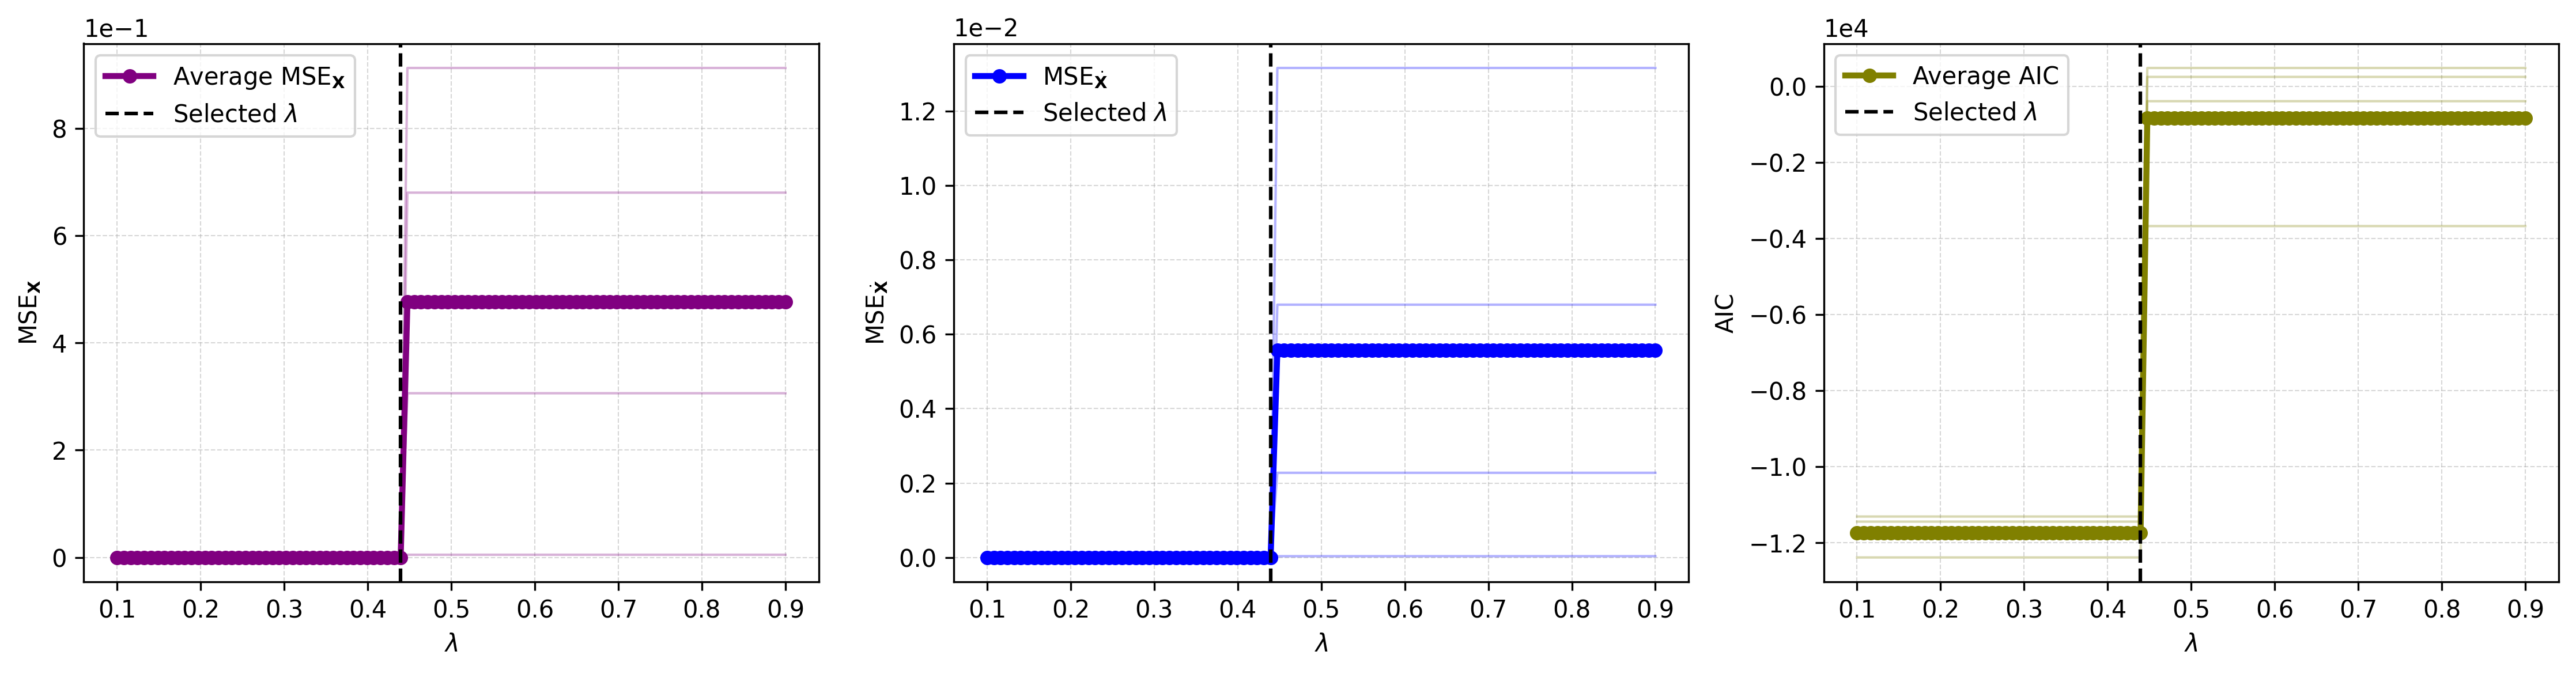

In [85]:
plot_mse_aic_vs_lambda_many_IC(pareto_data_dict, dpi=300)

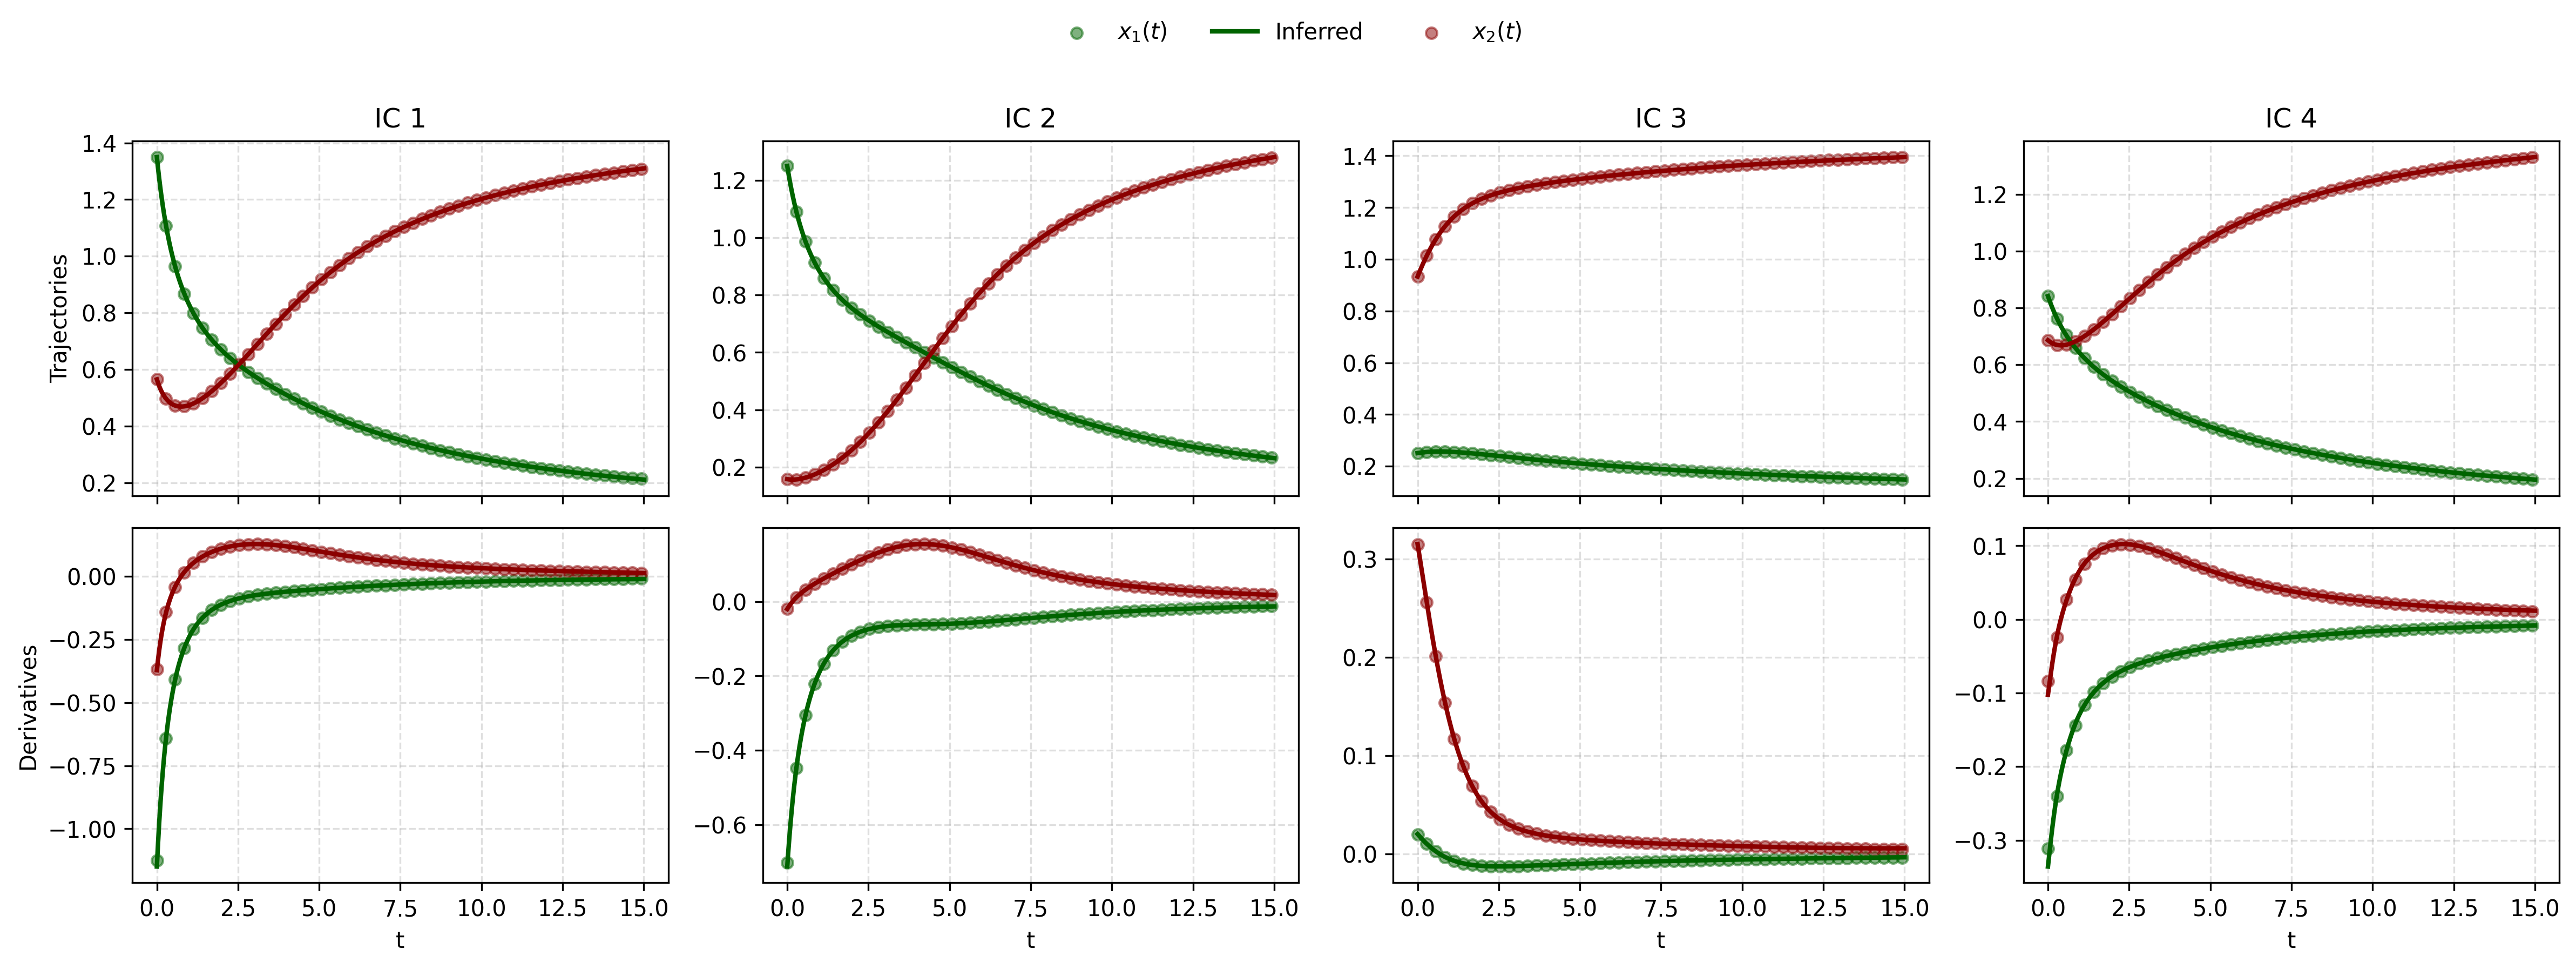


-==================== Sparsity in ST-LSq ====================-
Sparsity Threshold (λ): 0.4393939
Noise Amplitude       : 0.00%
Number of ICs         : 4

-==================== Ground Truth Xi ====================-
[[ 0.75057306  0.        ]
 [ 0.          1.58320314]
 [-1.          0.        ]
 [ 0.         -1.        ]
 [-0.4495459  -1.24339033]]

-==================== Identified Xi ====================-
[[ 0.74759078  0.        ]
 [ 0.          1.58177221]
 [-0.99743503  0.        ]
 [ 0.         -0.9992519 ]
 [-0.44724599 -1.24170101]]

-==================== Error Metrics Table ====================-
      Variable        MSE  Relative Error  Relative Error (NZ)
            x1 4.1525e-06          0.0034               0.0039
            x2 1.0922e-06          0.0010               0.0010
Model (global) 2.6224e-06             NaN               0.0024

-==================== Global Summary ====================-
Frobenius Norm            : 5.1209e-03
Relative Frobenius Norm   : 1.9612e-03

In [86]:
i = None
plot_final_traj_and_deriv_multiIC(pareto_data_dict, test, test_dot, t_test, N=15, idx=i, dpi=300)
print_results(control_data, pareto_data_dict, idx=i)

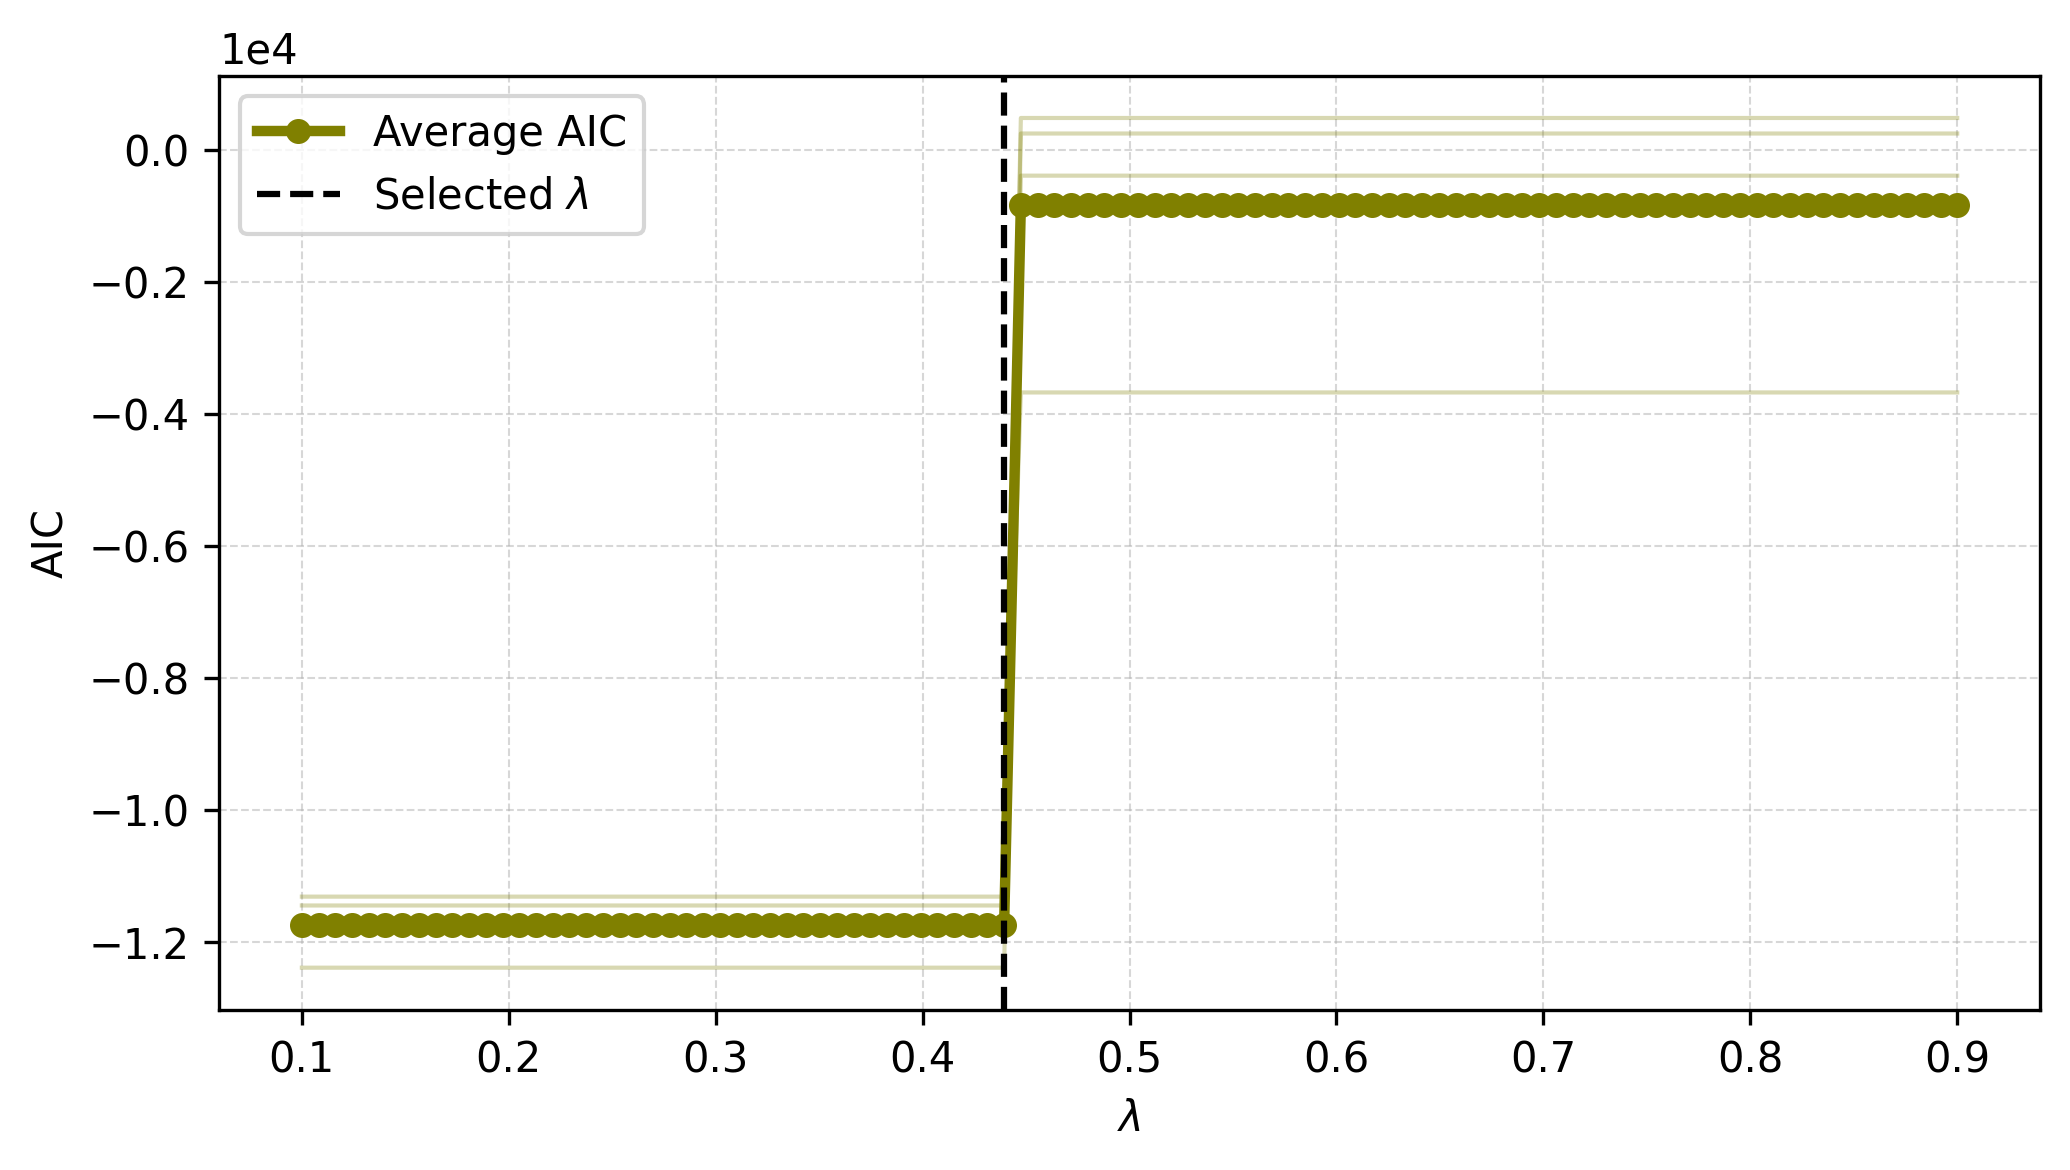

In [87]:
plot_aic_vs_lambda_many_IC(pareto_data_dict, dpi=300)